My dataset has bright foci on the feeding channel on the FISH images. For this reason, I need to use the summed FISH channels as a fake segmentation marker. However, they have bright foci that make the trench row identification not work.

Here, I try to use the BF channel that I took to Filter out the feeding channels from the FISH channel

In [1]:
# import paulssonlab.deaton.trenchripper.trenchripper as tr
# import trenchripper as tr
import trenchripper as tr

import warnings

warnings.filterwarnings(action="once")

import matplotlib

matplotlib.rcParams["figure.figsize"] = [20, 10]

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
import h5py

from skimage import io

headpath = '/home/lag36/scratch/lag36/2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch/Barcodes/'
kymoclust = tr.kymograph_cluster(headpath=headpath,paramfile=False)

In [27]:
# Import sum-of-all-FISH-channels image stack
file_idx = 0
headpath = '/home/lag36/scratch/lag36/2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch/Barcodes/'
channel_name = 'seg'
with h5py.File(headpath+"/hdf5_"+str(file_idx)+".hdf5","r") as imported_hdf5_handle:
    img_fish_sum = imported_hdf5_handle[channel_name][:] #t x y
# plt.imshow(img_fish_sum[0], cmap='gray')
# plt.show()
# plt.close()

# Import BF image stack
headpath = '/home/lag36/scratch/lag36/2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch/'
path_BF_stack = headpath+'Stack_XY50_BF.tif'
img_bf = io.imread(path_BF_stack)
# plt.imshow(img_bf[0], cmap='gray')
# plt.show()
# plt.close()

# Get an example phenotype dataframe
filename = '/home/lag36/scratch/lag36/2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch/Growth_Division/hdf5/hdf5_10.hdf5'
file_idx = 0
with h5py.File(filename,"r") as imported_hdf5_handle:
    # img_phenotype = imported_hdf5_handle[kymoclust.seg_channel][:] #t x y
    img_phenotype = imported_hdf5_handle['mCherry'][file_idx: file_idx+2] #t x y

# plt.imshow(img_phenotype[0], cmap='gray', vmin=0, vmax=2000)
# plt.show()
# plt.close()

In [28]:
# Delete all attributes of kymoclust
for attr in list(kymoclust.__dict__.keys()):
    delattr(kymoclust, attr)

In [38]:
kymoclust.y_percentile = 95
kymoclust.y_foreground_percentile = 65
kymoclust.smoothing_kernel_y = (1, 51)
kymoclust.y_percentile_threshold = 0.5
kymoclust.y_min_edge_dist = 50
kymoclust.invert=False

In [39]:
import skimage as sk
def get_smoothed_y_percentiles_from_array(img_arr,
                                          kymoclust,
                                          invert:bool,  
                                          y_percentile,
                                          y_foreground_percentile,
                                          smoothing_kernel_y):
    """For each imported array, computes the percentile along the x-axis of
    the segmentation channel, generating a (y,t) array. Then performs
    median filtering of this array for smoothing.

    Args:
        imported_hdf5_handle (h5py.File): Hdf5 file handle corresponding to the input hdf5 dataset
        "data" of shape (channel,y,x,t).
        y_percentile (int): Percentile to apply along the x-axis.
        smoothing_kernel_y (tuple): Kernel to use for median filtering.

    Returns:
        h5py.File: Hdf5 file handle corresponding to the output hdf5 dataset "data", a smoothed
        percentile array of shape (y,t).
    """
    if invert:
        img_arr = sk.util.invert(img_arr)
    perc_arr = np.percentile(img_arr,y_percentile,axis=2,interpolation='lower')
    y_percentiles_smoothed = kymoclust.median_filter_2d(perc_arr,smoothing_kernel_y)

    min_qth_percentile = y_percentiles_smoothed.min(axis=1)[:, np.newaxis]
##             max_qth_percentile = y_percentiles_smoothed.max(axis=1)[:, np.newaxis]
    max_qth_percentile = np.percentile(y_percentiles_smoothed,y_foreground_percentile,axis=1)[:, np.newaxis]
    y_percentiles_smoothed = (y_percentiles_smoothed - min_qth_percentile)/(max_qth_percentile - min_qth_percentile)
    y_percentiles_smoothed = np.minimum(y_percentiles_smoothed,1.)

    return y_percentiles_smoothed

In [40]:
def testing_get_trench_edges(img_arr, vmin=None, vmax=None):
    smoothed_y_percentiles = get_smoothed_y_percentiles_from_array(img_arr=img_arr,
                                                                   kymoclust=kymoclust,
                                                                   invert=kymoclust.invert,
                                                                   y_percentile=kymoclust.y_percentile,
                                                                   y_foreground_percentile=kymoclust.y_foreground_percentile,
                                                                   smoothing_kernel_y=kymoclust.smoothing_kernel_y)

    trench_mask_y = smoothed_y_percentiles>kymoclust.y_percentile_threshold

    trench_edges_y = kymoclust.get_trench_edges_y(y_percentiles_smoothed_array = smoothed_y_percentiles,
                                    y_percentile_threshold=kymoclust.y_percentile_threshold,
                                    y_min_edge_dist=kymoclust.y_min_edge_dist)

    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    ax[0].imshow(img_arr[0], cmap='gray', vmin=vmin, vmax=vmax)
    ax[1].plot(smoothed_y_percentiles[0])
    ax[1].set_title('Smoothed Y Percentiles')
    ax[2].plot(trench_mask_y[0])
    ax[2].set_title('Trench Mask Y')
    ax[3].plot(trench_mask_y[0])
    ax[3].vlines(trench_edges_y[0],0,1, color='r', lw=1)
    ax[3].set_title('Trench Edges Y')
    plt.tight_layout()
    plt.show()
    plt.close()

    return trench_edges_y

/tmp/ipykernel_93434/1276279657.py:24: DeprecationWarning: the `interpolation=` argument to percentile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  perc_arr = np.percentile(img_arr,y_percentile,axis=2,interpolation='lower')


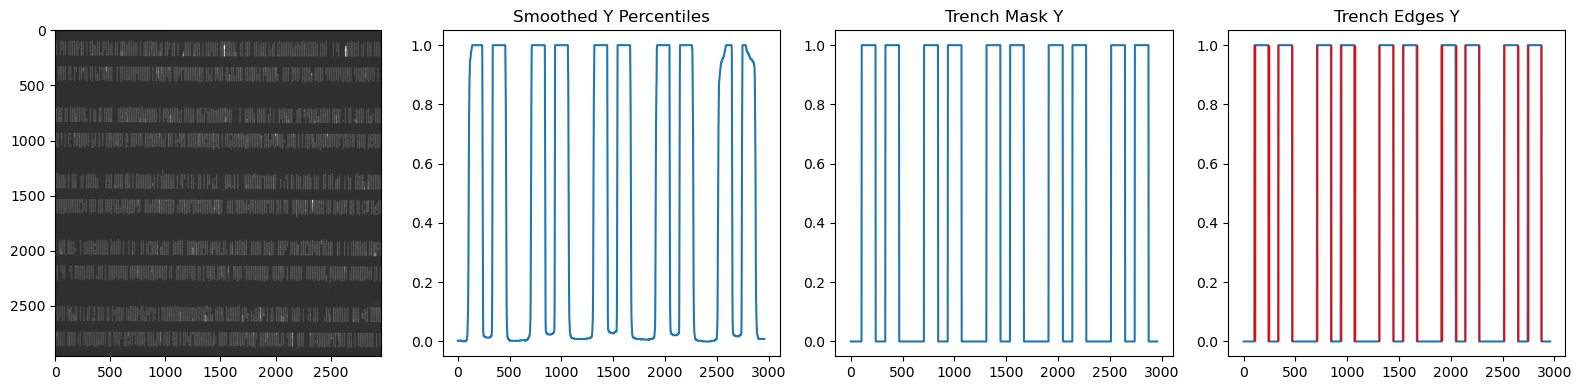

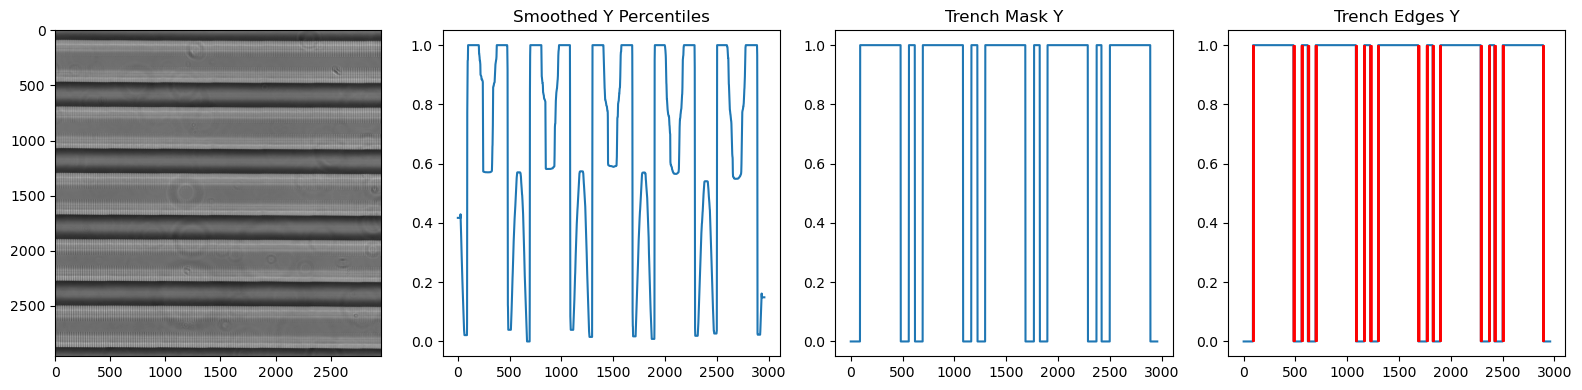

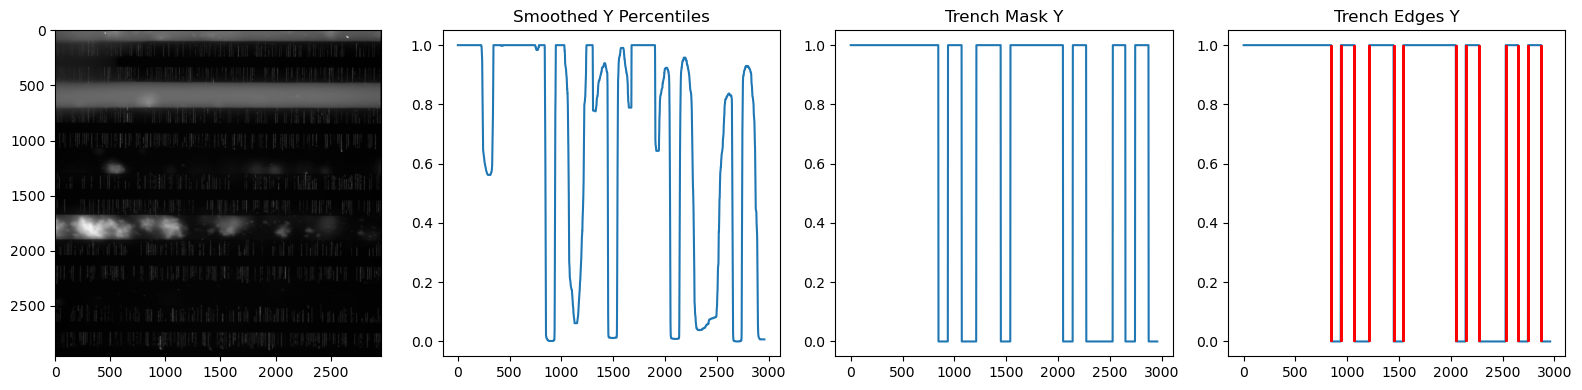

In [41]:
_ = testing_get_trench_edges(img_arr = img_phenotype, vmin = 0, vmax = 2000)
trench_edges_y = testing_get_trench_edges(img_arr = img_bf)
_ = testing_get_trench_edges(img_fish_sum)

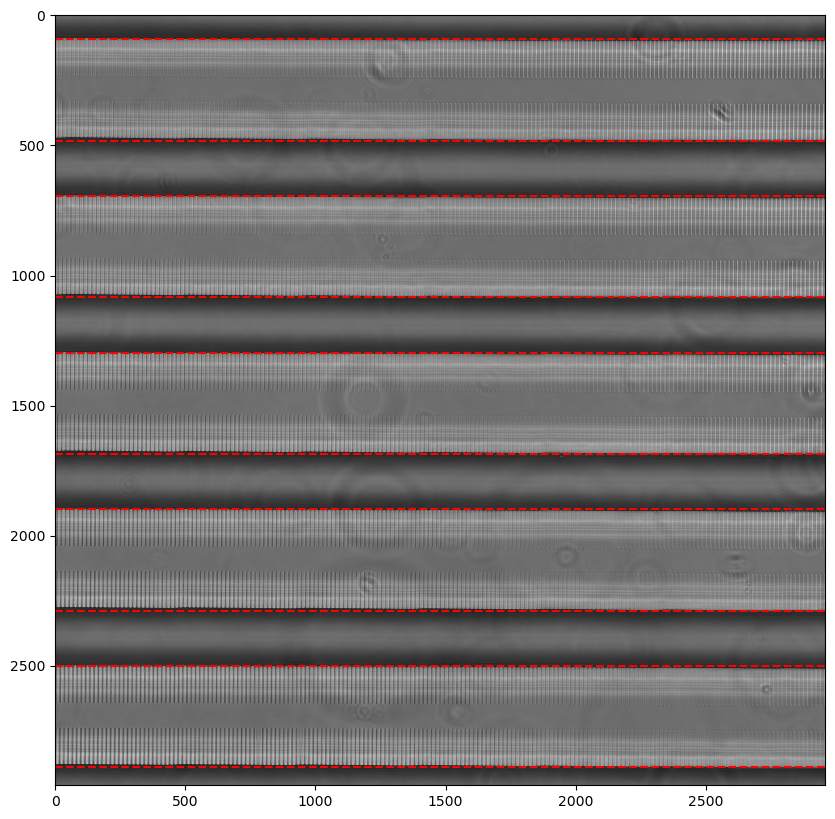

In [42]:
# Filter boundaries to only have feeding channel
# for i in range(len(trench_edges_y[0])):
#     print(trench_edges_y[0][i].shape)
# Get ffeeding channel edges
feeding_channel_boundary_indices = [0,
                                    1, 4,
                                    5, 8,
                                    9, 12,
                                    13, 16,
                                    17]

# Assuming no errors # TODO ACCOUNT FOR ERRORS
feeding_channel_edges = [trench_edges_y[0][i][feeding_channel_boundary_indices] for i in range(len(trench_edges_y[0]))]

time_index = 0
# Plot lines on top of the image
plt.imshow(img_bf[time_index], cmap='gray')
feeding_channel_edges_time = feeding_channel_edges[time_index]
# Draw horizontal lines at each edge
for edge in feeding_channel_edges_time:
    plt.axhline(y=edge, color='r', linestyle='--')

In [43]:
# Make mask for feeding channels
buffer_size = 3 # pixels
def generate_feeding_channel_mask_per_timepoint(feeding_channel_edges_time, shape):
    """
    Generate a mask for the feeding channels based on the edges provided.

    Parameters:
    - feeding_channel_edges_time: List of edges for the feeding channels at a specific timepoint.
    - shape: Shape of the mask to be generated.

    Returns:
    - mask: A boolean mask with True values in the feeding channel regions.
    """
    # mask_feeding_channels = np.zeros_like(BF[0], dtype=bool)
    # mask_feeding_channels[:feeding_channel_edges_time[0], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[1]:feeding_channel_edges_time[2], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[3]:feeding_channel_edges_time[4], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[5]:feeding_channel_edges_time[6], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[7]:feeding_channel_edges_time[8], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[9]:, :] = True
    mask = np.zeros(shape, dtype=bool)
    for i in range(0, len(feeding_channel_edges_time), 2):
        mask[feeding_channel_edges_time[i]+buffer_size:feeding_channel_edges_time[i+1]-buffer_size, :] = True
    return mask

mask_all_timepoints = np.zeros(img_bf.shape, dtype=bool)
for time_index in range(img_bf.shape[0]):
    feeding_channel_edges_time = feeding_channel_edges[time_index]
    mask_feeding_channels = generate_feeding_channel_mask_per_timepoint(feeding_channel_edges_time, img_bf[0].shape)
    mask_all_timepoints[time_index] = mask_feeding_channels

In [44]:
img_fish_sum_masked = img_fish_sum * mask_all_timepoints

/tmp/ipykernel_93434/1276279657.py:24: DeprecationWarning: the `interpolation=` argument to percentile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  perc_arr = np.percentile(img_arr,y_percentile,axis=2,interpolation='lower')


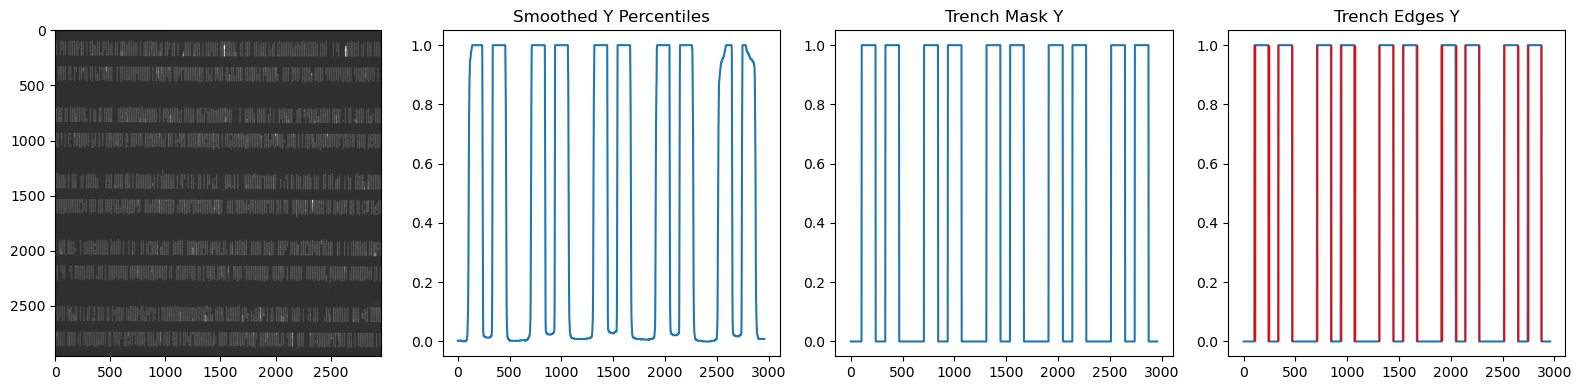

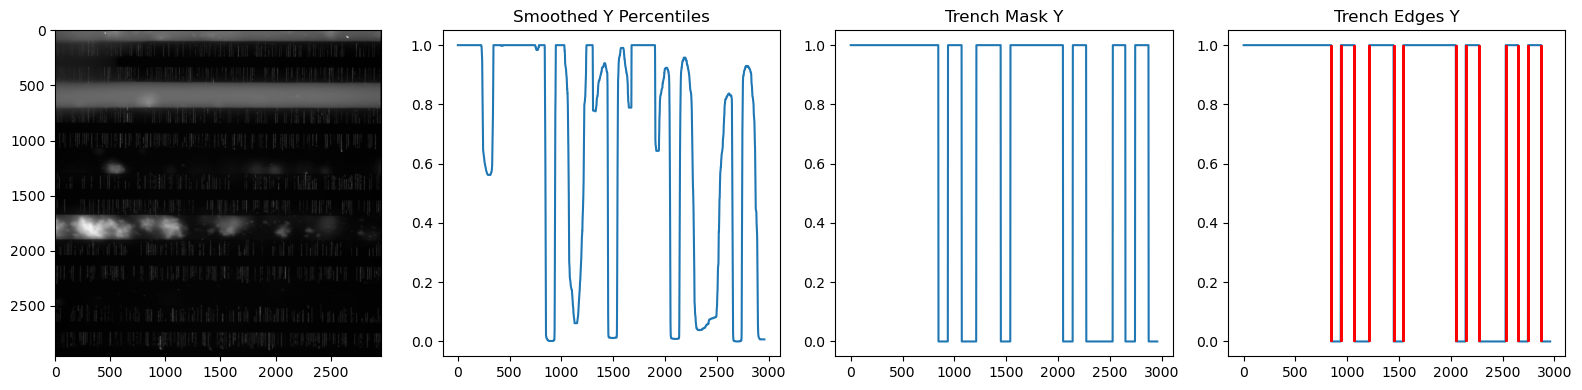

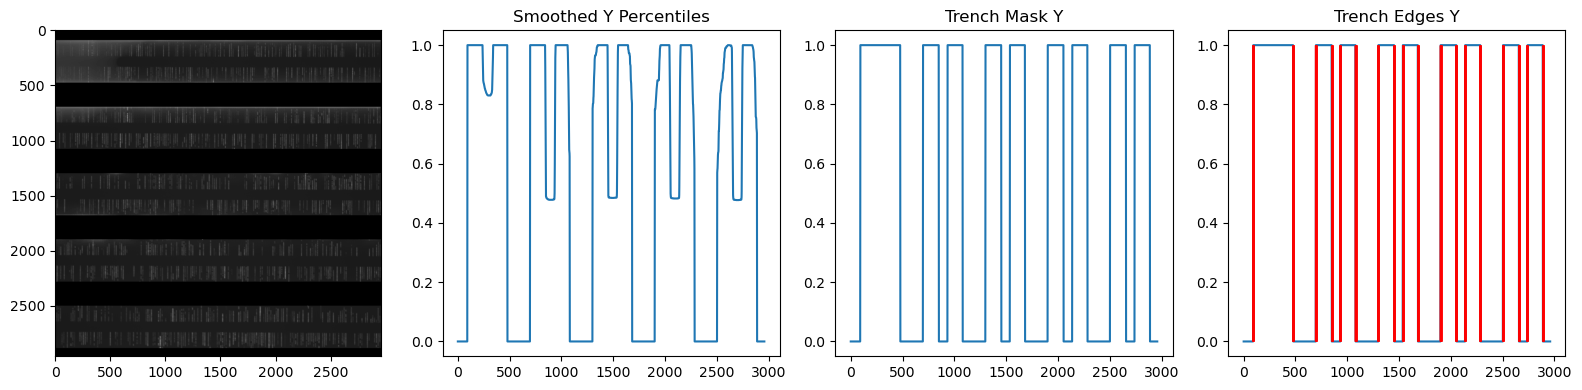

In [45]:
_ = testing_get_trench_edges(img_arr = img_phenotype, vmin = 0, vmax = 2000)
# trench_edges_y = testing_get_trench_edges(img_arr = img_bf)
_ = testing_get_trench_edges(img_fish_sum)
_ = testing_get_trench_edges(img_fish_sum_masked)

## Version to deploy

In [48]:
headpath = '/home/lag36/scratch/lag36/2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch/Barcodes/'

In [50]:
with h5py.File(headpath+"/hdf5_0.hdf5","r") as imported_hdf5_handle:
    img_bf_test_0 = imported_hdf5_handle['BF'][:] #t x y

with h5py.File(headpath+"/hdf5_50.hdf5","r") as imported_hdf5_handle:
    img_bf_test_50 = imported_hdf5_handle['BF'][:] #t x y

with h5py.File(headpath+"/hdf5_594.hdf5","r") as imported_hdf5_handle:
    img_bf_test_594 = imported_hdf5_handle['BF'][:] #t x y


/tmp/ipykernel_93434/1276279657.py:24: DeprecationWarning: the `interpolation=` argument to percentile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  perc_arr = np.percentile(img_arr,y_percentile,axis=2,interpolation='lower')


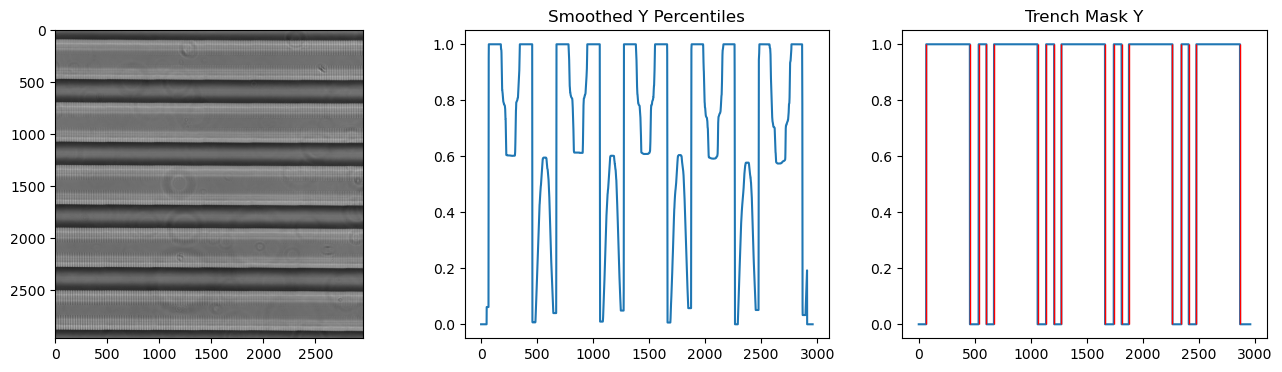

In [54]:
smoothed_y_percentiles = get_smoothed_y_percentiles_from_array(img_arr=img_bf_test_594,
                                        kymoclust=kymoclust,
                                        invert=kymoclust.invert,
                                     y_percentile=kymoclust.y_percentile,
                                     y_foreground_percentile=kymoclust.y_foreground_percentile,
                                     smoothing_kernel_y=kymoclust.smoothing_kernel_y)

# Trim edges
smoothed_y_percentiles[:,:BUFFER_IMAGE_EDGE_PIXELS] = 0
smoothed_y_percentiles[:,-BUFFER_IMAGE_EDGE_PIXELS:] = 0

trench_mask_y = smoothed_y_percentiles>kymoclust.y_percentile_threshold
trench_edges_y_594,start_above_list,end_above_list = kymoclust.get_edges_from_mask(trench_mask_y)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].imshow(img_bf_test_50[0], cmap='gray')
ax[1].plot(smoothed_y_percentiles[0])
ax[1].set_title('Smoothed Y Percentiles')
ax[2].plot(trench_mask_y[0])
ax[2].set_title('Trench Mask Y')
ax[2].vlines(trench_edges_y_594[0],0,1, color='r', lw=1)


/tmp/ipykernel_93434/1276279657.py:24: DeprecationWarning: the `interpolation=` argument to percentile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  perc_arr = np.percentile(img_arr,y_percentile,axis=2,interpolation='lower')


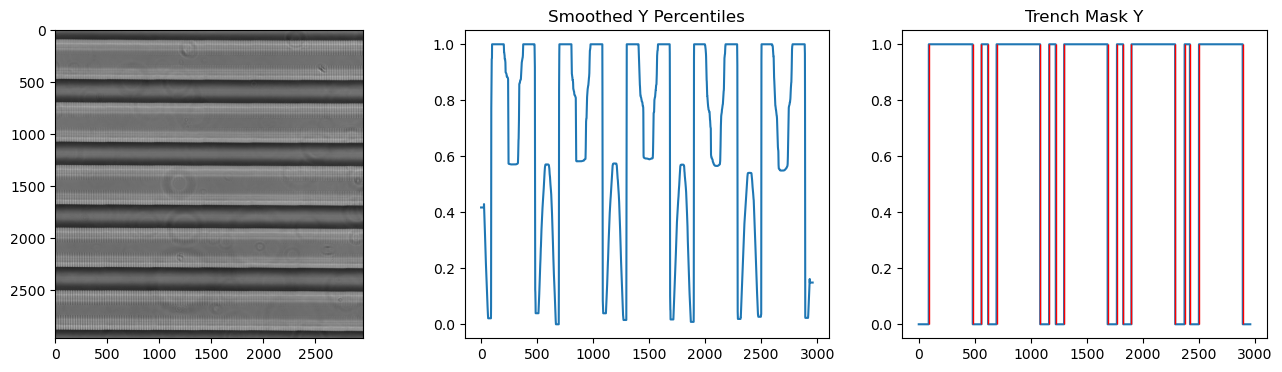

In [57]:
smoothed_y_percentiles = get_smoothed_y_percentiles_from_array(img_arr=img_bf_test_50,
                                        kymoclust=kymoclust,
                                        invert=kymoclust.invert,
                                     y_percentile=kymoclust.y_percentile,
                                     y_foreground_percentile=kymoclust.y_foreground_percentile,
                                     smoothing_kernel_y=kymoclust.smoothing_kernel_y)

# smoothed_y_percentiles[:,:BUFFER_IMAGE_EDGE_PIXELS] = 0
trench_mask_y = smoothed_y_percentiles>kymoclust.y_percentile_threshold
trench_edges_y_50,start_above_list,end_above_list = kymoclust.get_edges_from_mask(trench_mask_y)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].imshow(img_bf_test_50[0], cmap='gray')
ax[1].plot(smoothed_y_percentiles[0])
ax[1].set_title('Smoothed Y Percentiles')
ax[2].plot(trench_mask_y[0])
ax[2].set_title('Trench Mask Y')
ax[2].vlines(trench_edges_y_50[0],0,1, color='r', lw=1)


/tmp/ipykernel_93434/1276279657.py:24: DeprecationWarning: the `interpolation=` argument to percentile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  perc_arr = np.percentile(img_arr,y_percentile,axis=2,interpolation='lower')


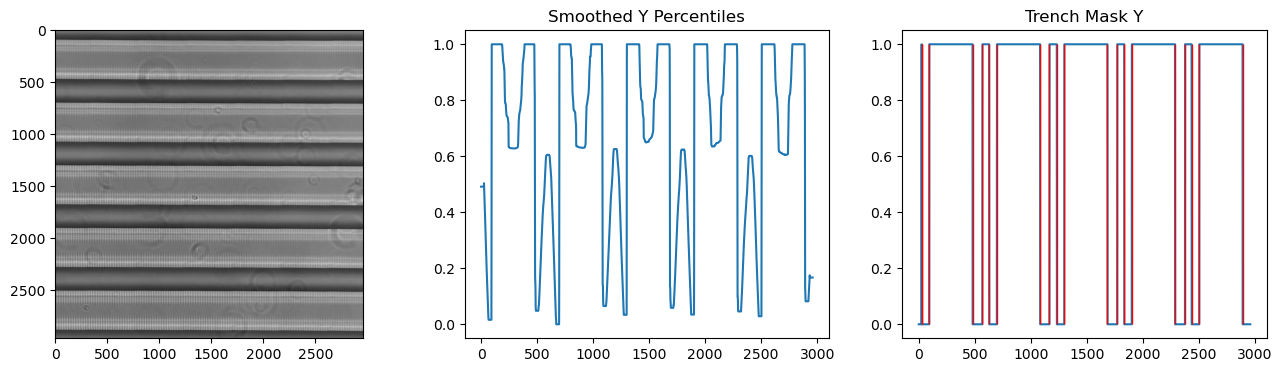

In [58]:
smoothed_y_percentiles = get_smoothed_y_percentiles_from_array(img_arr=img_bf_test_0,
                                        kymoclust=kymoclust,
                                        invert=kymoclust.invert,
                                     y_percentile=kymoclust.y_percentile,
                                     y_foreground_percentile=kymoclust.y_foreground_percentile,
                                     smoothing_kernel_y=kymoclust.smoothing_kernel_y)
# smoothed_y_percentiles[:,:BUFFER_IMAGE_EDGE_PIXELS] = 0
trench_mask_y = smoothed_y_percentiles>kymoclust.y_percentile_threshold
trench_edges_y_0 ,start_above_list,end_above_list = kymoclust.get_edges_from_mask(trench_mask_y)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].imshow(img_bf_test_0[0], cmap='gray')
ax[1].plot(smoothed_y_percentiles[0])
ax[1].set_title('Smoothed Y Percentiles')
ax[2].plot(trench_mask_y[0])
ax[2].set_title('Trench Mask Y')
ax[2].vlines(trench_edges_y_0[0],0,1, color='r', lw=1)

In [59]:
FEEDING_CHANNEL_BUFFER_SIZE_PIXELS = 3
BUFFER_IMAGE_EDGE_PIXELS = 50

def get_feeding_channel_edges(img_arr):
    smoothed_y_percentiles = kymoclust.get_smoothed_y_percentiles_from_array(img_arr=img_arr,
                                     y_percentile=kymoclust.y_percentile,
                                     y_foreground_percentile=kymoclust.y_foreground_percentile,
                                     smoothing_kernel_y=kymoclust.smoothing_kernel_y)
    
    # Trim edges to avoid unwanted peaks
    smoothed_y_percentiles[:,:BUFFER_IMAGE_EDGE_PIXELS] = 0
    smoothed_y_percentiles[:,-BUFFER_IMAGE_EDGE_PIXELS:] = 0

    trench_edges_y , _, _ = kymoclust.get_trench_edges_y(y_percentiles_smoothed_array = smoothed_y_percentiles,
                                    y_percentile_threshold=kymoclust.y_percentile_threshold,
                                    y_min_edge_dist=kymoclust.y_min_edge_dist)
    
    # Convert to numpy array and validate its shape
    # This will fail if shapes are not consistent (i.e. different number of peaks found at different timepoints)
    trench_edges_y = np.array(trench_edges_y)
    if trench_edges_y.shape[0] != 15 or trench_edges_y.shape[1] != 18:
        raise ValueError(f"Expected shape (18, 15) elements, but got shape ({trench_edges_y.shape}).")

    # Get the feeding channel edges
    feeding_channel_boundary_indices = [0,
                                        1, 4,
                                        5, 8,
                                        9, 12,
                                        13, 16,
                                        17]
    
    feeding_channel_edges = trench_edges_y[:, feeding_channel_boundary_indices]

    # mask_feeding_channels = np.zeros(img_arr.shape, dtype=bool)
    # for i in range(0, len(feeding_channel_edges), 2):
    #     mask_feeding_channels[feeding_channel_edges[i]:feeding_channel_edges[i+1], :] = True

    return feeding_channel_edges

def generate_feeding_channel_mask_per_timepoint(feeding_channel_edges_timepoint, buffer_size_pixels, shape):
    """
    Generate a mask for the feeding channels based on the edges provided.

    Parameters:
    - feeding_channel_edges_time: List of edges for the feeding channels at a specific timepoint.
    - shape: Shape of the mask to be generated.

    Returns:
    - mask: A boolean mask with True values in the feeding channel regions.
    """
    # mask_feeding_channels = np.zeros_like(BF[0], dtype=bool)
    # mask_feeding_channels[:feeding_channel_edges_time[0], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[1]:feeding_channel_edges_time[2], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[3]:feeding_channel_edges_time[4], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[5]:feeding_channel_edges_time[6], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[7]:feeding_channel_edges_time[8], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[9]:, :] = True
    mask = np.zeros(shape, dtype=bool)
    for i in range(0, len(feeding_channel_edges_timepoint), 2):
        mask[feeding_channel_edges_timepoint[i]+buffer_size_pixels:feeding_channel_edges_timepoint[i+1]-buffer_size_pixels, :] = True
    return mask

def generate_feeding_channel_mask_all_timepoints(feeding_channel_edges, shape):
    mask_all_timepoints = np.zeros(shape, dtype=bool)
    for time_index in range(shape[0]):
        mask_feeding_channels = generate_feeding_channel_mask_per_timepoint(feeding_channel_edges[time_index], FEEDING_CHANNEL_BUFFER_SIZE_PIXELS, shape[1:])
        mask_all_timepoints[time_index] = mask_feeding_channels

    return mask_all_timepoints

def clean_feeding_channels(img_arr_to_clean, img_array_to_find_feeding_channels):
    feeding_channel_edges = get_feeding_channel_edges(img_array_to_find_feeding_channels)
    mask_all_timepoints = generate_feeding_channel_mask_all_timepoints(feeding_channel_edges, img_array_to_find_feeding_channels.shape)

    img_arr_masked = img_arr_to_clean * mask_all_timepoints
    return img_arr_masked
def create_fake_seg_channel(filepath, fish_channels = ["RFP", "Cy5"], seg_channel_name = 'seg'):
    """
    Create a synthetic segmentation channel based on the provided fish channels.
    The synthetic channel is generated by taking the 98th percentile projection of each fish channel,
    normalizing it, and then combining them into a single channel.
    The resulting synthetic channel is saved in the HDF5 file with the specified name.

    Parameters:
    - filepath (str): Path to the HDF5 file.
    - fish_channels (list): List of fish channel names to be used for generating the synthetic channel.
    - seg_channel_name (str): Name for the synthetic segmentation channel to be saved in the HDF5 file.
    """
    with h5py.File(filepath,"r+") as infile:

        n_timepoints = infile[fish_channels[0]].shape[0]
        img_dimensions = infile[fish_channels[0]].shape[1:]
        # dimesions (N_channels, Y, X)
        percentile_projections = np.zeros((len(fish_channels), *img_dimensions))
            
        for i, channel in enumerate(fish_channels):
            channel_arr = np.percentile(infile[channel][:],98,axis=0)
            channel_arr = channel_arr/channel_arr.max()
            percentile_projections[i] = channel_arr
        
        percentile_projection_all_channels = 10000*np.percentile(percentile_projections,98,axis=0)
        percentile_projection_all_channels_times = np.stack(
            [percentile_projection_all_channels for i in range(n_timepoints)],axis=0).astype("uint16")

        if seg_channel_name in infile.keys():
            del infile[seg_channel_name]
        infile[seg_channel_name] = percentile_projection_all_channels_times
    return 0

def clean_feeding_channels_hdf5(filepath,
                                channel_to_find_feeding_channels = 'BF',
                                channel_to_clean_feeding_channels = 'seg',
                                channel_name_cleaned_feeding_channels = 'seg_cleaned'):
    """
    Clean the feeding channels in an HDF5 file.

    Parameters:
    - filepath (str): Path to the HDF5 file.
    - channel_to_find_feeding_channels (str): Name of the channel used to identify feeding channels.
    - channel_to_rm_feeding_channels (str): Name of the channel from which to remove feeding channels.
    - channel_name_cleaned_feeding_channels (str): Name for the cleaned feeding channels to be saved in the HDF5 file.
    """
    
    with h5py.File(filepath,"r+") as infile:
        img_arr_to_clean = infile[channel_to_clean_feeding_channels]
        img_array_to_find_feeding_channels = infile[channel_to_find_feeding_channels]

        img_arr_masked = clean_feeding_channels(img_arr_to_clean, img_array_to_find_feeding_channels)

        if channel_name_cleaned_feeding_channels in infile.keys():
            del infile[channel_name_cleaned_feeding_channels]
        infile[channel_name_cleaned_feeding_channels] = img_arr_masked
    
    return 0

In [141]:
import glob
headpath = '/home/lag36/scratch/lag36/2025-02-20_lLAG8-MBM-37C-Run-05_3-Fids_Auto-Switch/Barcodes/hdf5/'
full_filepaths_hdf5 = glob.glob(headpath + '/hdf5_*.hdf5')
filenames_hdf5 = [filename.split('/')[-1] for filename in full_filepaths_hdf5]

In [143]:
len(filenames_hdf5)

629

In [ ]:
# filepath = headpath + '/hdf5_0.hdf5'
# clean_feeding_channels_hdf5(filepath=filepath,
#                             channel_to_find_feeding_channels = 'BF',
#                             channel_to_clean_feeding_channels = 'seg',
#                             channel_name_cleaned_feeding_channels = 'seg_cleaned')

# with h5py.File(filepath,"r") as infile:
#     keys = infile.keys()
#     print(keys)
#     fig, ax = plt.subplots(1, len(keys), figsize=(5*len(keys), 5))
#     for i, key in enumerate(keys):
#         ax[i].imshow(infile[key][10], cmap='gray')
#         ax[i].set_title(key)

## Parallel

In [127]:
dask_wd = "/home/lag36/scratch/lag36/dask"
dask_controller = tr.trcluster.dask_controller(
    walltime="2:00:00",
    local=False,
    n_workers=300,
    n_workers_min=20,
    memory="3GB",
    working_directory=dask_wd,
)
dask_controller.startdask()

110m
2:00:00


In [128]:
dask_controller.displaydashboard()

In [129]:
filenames_hdf5

['hdf5_0.hdf5',
 'hdf5_100.hdf5',
 'hdf5_50.hdf5',
 'hdf5_594.hdf5',
 'hdf5_60.hdf5']

In [130]:
futures = []
futures_dict = {}
for filename in filenames_hdf5:
    print(filename)
    future = dask_controller.daskclient.submit(create_fake_seg_channel, 
                           headpath+filename,
                           fish_channels = ["RFP", "Cy5"],
                           seg_channel_name = 'seg',
                           )
    futures.append(future)
    futures_dict[filename] = future
results = dask_controller.daskclient.gather(futures)

hdf5_0.hdf5
hdf5_100.hdf5
hdf5_50.hdf5
hdf5_594.hdf5
hdf5_60.hdf5


In [136]:
futures_dict

{'hdf5_0.hdf5': <Future: finished, type: int, key: clean_feeding_channels_hdf5-cf0b6b9df768e1b7ab25b60cae8d3e76>,
 'hdf5_100.hdf5': <Future: finished, type: int, key: clean_feeding_channels_hdf5-d61cbd8ff0d9b64b285302bb0d2156cb>,
 'hdf5_50.hdf5': <Future: finished, type: int, key: clean_feeding_channels_hdf5-59f406e578029321883427a0adce67f4>,
 'hdf5_594.hdf5': <Future: finished, type: int, key: clean_feeding_channels_hdf5-2f1be1fcdd59003e55edbda7ba8ea211>,
 'hdf5_60.hdf5': <Future: finished, type: int, key: clean_feeding_channels_hdf5-304b409239f16fe154639c4d096ac328>}

In [101]:
failed_runs = {}
futures = []

In [132]:
futures = []
futures_dict = {}
for filename in filenames_hdf5:
    print(filename)
    future = dask_controller.daskclient.submit(clean_feeding_channels_hdf5,
                           headpath+filename,
                           channel_to_find_feeding_channels = 'BF',
                           channel_to_clean_feeding_channels = 'seg',
                           channel_name_cleaned_feeding_channels = 'seg_cleaned')
    futures.append(future)
    futures_dict[filename] = future
results = dask_controller.daskclient.gather(futures)

hdf5_0.hdf5
hdf5_100.hdf5
hdf5_50.hdf5
hdf5_594.hdf5
hdf5_60.hdf5


<KeysViewHDF5 ['BF', 'Cy5', 'RFP']>


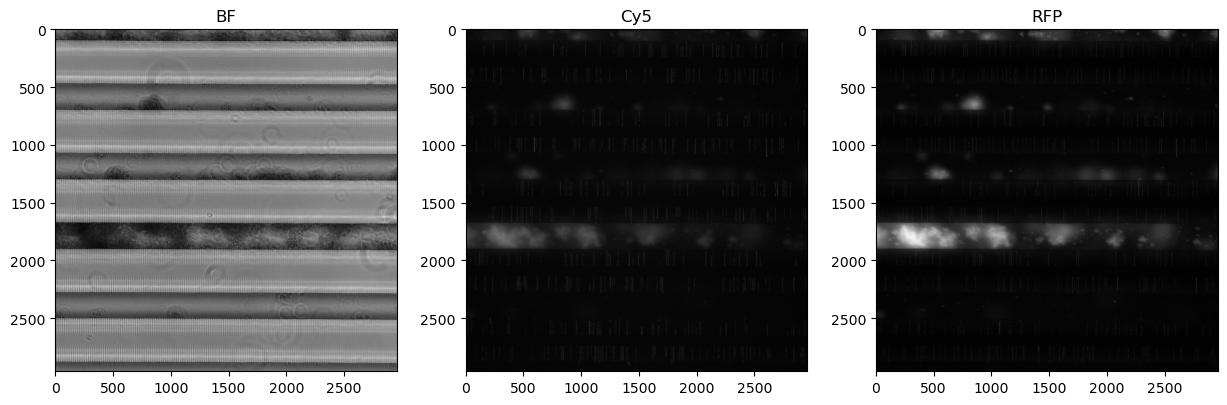

In [138]:
filepath = headpath + '/hdf5/hdf5_0.hdf5'
# clean_feeding_channels_hdf5(filepath=filepath,
#                             channel_to_find_feeding_channels = 'BF',
#                             channel_to_clean_feeding_channels = 'seg',
#                             channel_name_cleaned_feeding_channels = 'seg_cleaned')

with h5py.File(filepath,"r") as infile:
    keys = infile.keys()
    print(keys)
    fig, ax = plt.subplots(1, len(keys), figsize=(5*len(keys), 5))
    for i, key in enumerate(keys):
        ax[i].imshow(infile[key][10], cmap='gray')
        ax[i].set_title(key)